# Heisenberg model in emu_cheb, driven by a pulser sequence

`examples/emu_mps/heisenberg.ipynb`, run by `emu_cheb.ChebBackend` (the exact Chebyshev engines of `emu_cheb.solvers`, see
`emu_cheb/README.md`). The Hamiltonian is the same general Heisenberg (XYZ) one

$$
H(t) = \sum_j \frac{\Omega_j(t)}{2}\big[\cos\phi_j X_j + \sin\phi_j Y_j\big] - \sum_j \Delta_j(t)\, n_j
 + \sum_{i<j} \big( J^{xx}_{ij} X_iX_j + J^{yy}_{ij} Y_iY_j + J^{zz}_{ij} Z_iZ_j \big)
$$

with Pauli matrices $X, Y, Z$, $n = |d\rangle\langle d| = (1-Z)/2$, frequencies in rad/µs and times in ns.

Workflow (shorter than with emu-mps: no hand-made `SequenceData`):
1. build a normal pulser `Sequence` on the XY (`mw_global`) channel: register, pulses, noise model;
2. `ChebConfig(heisenberg=(Jxx, Jyy, Jzz) / J)` scales the sequence's dipolar couplings $J_{ij}$ into the
   $3\times n\times n$ stack (or pass any `(3, n, n)` stack directly);
3. `ChebBackend(seq, config).run()`: pulser `Results`, as emu-sv / emu-mps.

Every result is checked against an exact dense simulation: state vector without noise, Lindblad master equation with
noise, for a **pulsed** sequence and a **free** (no pulse) one.

In [1]:
import logging
import time
from functools import reduce

import matplotlib.pyplot as plt
import numpy as np
import pulser
import torch
from pulser.devices import MockDevice

from emu_base import PulserData
from emu_cheb import ChebBackend, ChebConfig, Energy, Occupation, StateResult, StateVector

dtype = torch.complex128

## 1. Register and pulser sequences

A chain of 6 atoms, 18 µm apart. Two sequences on the global microwave (XY) channel of `MockDevice`:
- **pulsed**: Blackman π-pulse with a linear detuning ramp from -3 to 3 rad/µs;
- **free**: a delay of the same duration, i.e. $\Omega=\Delta=0$, pure Heisenberg dynamics.

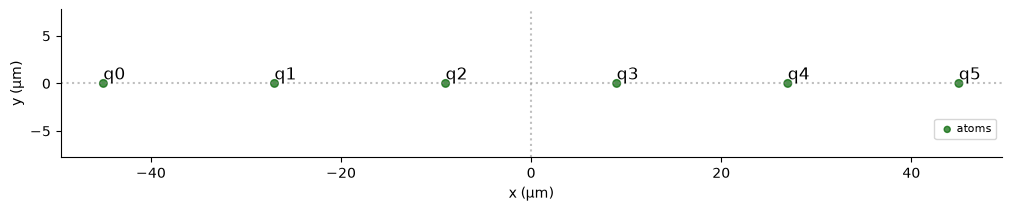

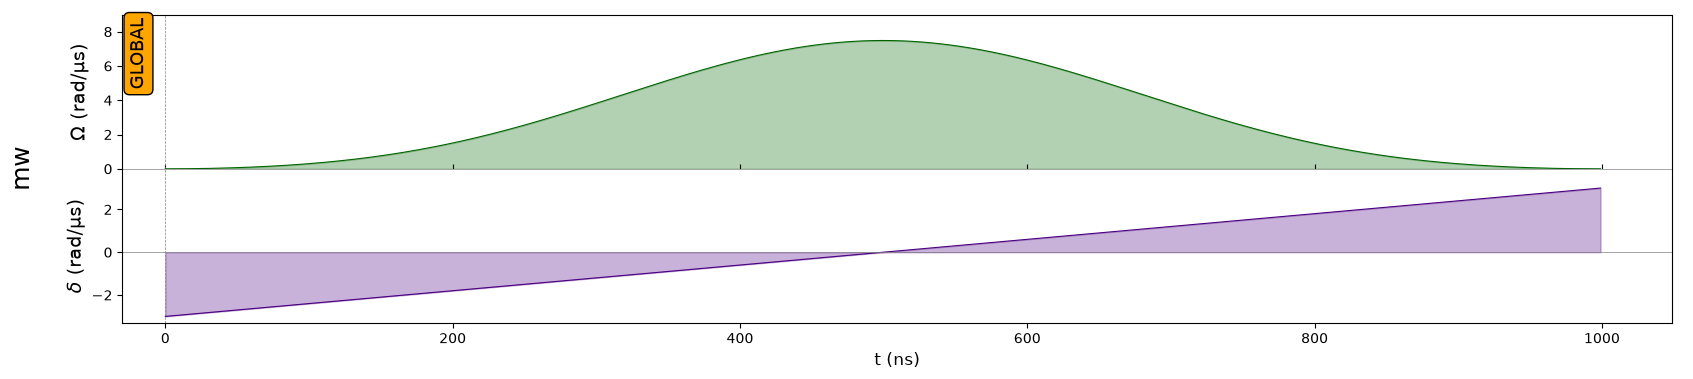

In [2]:
n, T, dt = 6, 1000, 10  # qubits, duration (ns), drive sampling step (ns)
reg = pulser.Register.rectangle(1, n, spacing=18.0, prefix="q")


def make_sequence(pulsed):
    seq = pulser.Sequence(reg, MockDevice)
    seq.declare_channel("mw", "mw_global")
    if pulsed:
        pulse = pulser.Pulse(
            amplitude=pulser.BlackmanWaveform(T, area=np.pi),
            detuning=pulser.RampWaveform(T, -3.0, 3.0),
            phase=0.0,
        )
        seq.add(pulse, "mw")
    else:
        seq.delay(T, "mw")
    return seq


sequences = {"pulsed": make_sequence(True), "free": make_sequence(False)}
reg.draw()
sequences["pulsed"].draw()

## 2. Heisenberg couplings

Pulser's XY interaction is the stack `[C3/r³ (1 - 3cos²θ), 0]`; `heisenberg=anisotropy` keeps the dipolar couplings
$J_{ij} = C_3(1-3\cos^2\theta_{ij})/r_{ij}^3$ and scales them per term: `(1, 1, 1)` is isotropic, e.g.
`(1, 0.7, 1.3)` an XYZ model. The `SequenceData` below (same sampling as the backend) only feeds the exact references.

/Users/i.sokolov/Code/emulators/ci/emu_cheb/emu_cheb/config.py:85: UserWarning: 'ChebConfig' was initialized without any observables. The corresponding emulation results will be empty.
  super().__init__(


100 steps of 10 ns; nearest-neighbour coupling 6.222 rad/µs


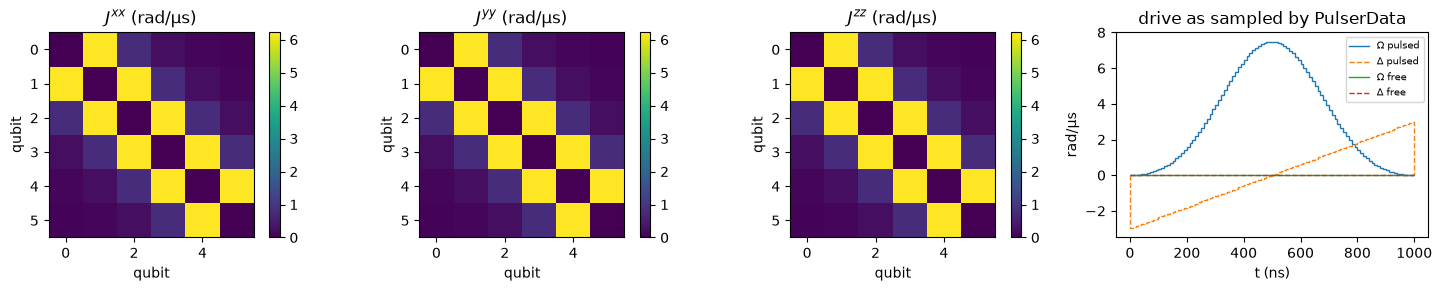

In [3]:
anisotropy = (1.0, 1.0, 1.0)
times = [k / 50 for k in range(51)]  # output every 20 ns, as fractions of T
rows = [round(t * T / dt) for t in times]  # their index on the dt grid of the exact references


def heisenberg_sequence_data(seq, noise_model=None):
    # the backend's own sampling and Heisenberg stack (emu_cheb.backend.heisenberg_samples), for the exact references
    from emu_cheb.backend import heisenberg_samples
    (sd,) = PulserData(sequence=seq, config=ChebConfig(dt=dt, noise_model=noise_model), dt=dt).get_sequences()
    return heisenberg_samples([sd], anisotropy)[0]


seq_data = {name: heisenberg_sequence_data(seq) for name, seq in sequences.items()}
J = seq_data["pulsed"].interaction_matrix(0.0)
print(f"{len(seq_data['pulsed'].target_times) - 1} steps of {dt} ns; nearest-neighbour coupling {J[0, 0, 1]:.3f} rad/µs")

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, Jk, name in zip(axes, J, ("$J^{xx}$", "$J^{yy}$", "$J^{zz}$")):
    fig.colorbar(ax.imshow(Jk, cmap="viridis"), ax=ax)
    ax.set_title(name + " (rad/µs)"); ax.set_xlabel("qubit"); ax.set_ylabel("qubit")
for name, s in seq_data.items():
    axes[3].stairs(s.omega[:, 0].real, s.target_times, label=rf"$\Omega$ {name}")
    axes[3].stairs(s.delta[:, 0].real, s.target_times, label=rf"$\Delta$ {name}", linestyle="--")
axes[3].set_xlabel("t (ns)"); axes[3].set_ylabel("rad/µs"); axes[3].legend(fontsize=7)
axes[3].set_title("drive as sampled by PulserData")
fig.tight_layout()

## 3. Exact references

Dense $2^n$ simulations driven by the very same `SequenceData` arrays: `omega[k]`, `delta[k]`, `phi[k]` are constant
on `[target_times[k], target_times[k+1]]`. The initial state is the Néel state $|udud\dots\rangle$ and we record
$\langle n_j \rangle(t)$, the population of $|d\rangle$ (what `Occupation` measures).

In [4]:
X = torch.tensor([[0, 1], [1, 0]], dtype=dtype)
Y = torch.tensor([[0, -1j], [1j, 0]], dtype=dtype)
Z = torch.tensor([[1, 0], [0, -1]], dtype=dtype)
Nd = torch.tensor([[0, 0], [0, 1]], dtype=dtype)


def op(single, i):
    # single-qubit operator on qubit i; qubit 0 is the most significant bit
    return reduce(torch.kron, [single if k == i else torch.eye(2, dtype=dtype) for k in range(n)])


N_ops = [op(Nd, j) for j in range(n)]
neel_bits = "".join(str(j % 2) for j in range(n))


def hamiltonians(sd):
    # one dense H per time step
    J = sd.interaction_matrix(0.0)
    H_int = sum(
        J[a, i, j] * op(P, i) @ op(P, j)
        for a, P in enumerate((X, Y, Z))
        for i in range(n)
        for j in range(i + 1, n)
    )
    w, d, p = sd.omega.real, sd.delta.real, sd.phi.real
    return [
        H_int + sum(
            w[k, j] / 2 * (torch.cos(p[k, j]) * op(X, j) + torch.sin(p[k, j]) * op(Y, j)) - d[k, j] * N_ops[j]
            for j in range(n)
        )
        for k in range(len(w))
    ]


def exact_state_dynamics(sd):
    # occupations and energies <H_k> (H of the step ending at each grid time, as emu-sv / emu_cheb) on the dt grid
    Hs = hamiltonians(sd)
    psi = torch.zeros(2**n, dtype=dtype)
    psi[int(neel_bits, 2)] = 1.0
    occ = [torch.stack([torch.vdot(psi, Nj @ psi).real for Nj in N_ops])]
    energy = [torch.vdot(psi, Hs[0] @ psi).real]
    for H, t0, t1 in zip(Hs, sd.target_times, sd.target_times[1:]):
        psi = torch.linalg.matrix_exp(-1j * H * (t1 - t0) / 1000) @ psi  # µs
        occ.append(torch.stack([torch.vdot(psi, Nj @ psi).real for Nj in N_ops]))
        energy.append(torch.vdot(psi, H @ psi).real)
    return torch.stack(occ), torch.stack(energy), psi


def exact_lindblad_dynamics(sd, n_sub=10):
    # RK4 on rho' = -i[H, rho] + sum_k L rho L^+ - 1/2 {L^+ L, rho}
    Ls = [op(L, j) for L in sd.lindblad_ops for j in range(n)]
    LdL = sum(L.mH @ L for L in Ls)

    def rhs(rho, H_eff):
        out = -1j * (H_eff @ rho - rho @ H_eff.mH)
        for L in Ls:
            out += L @ rho @ L.mH
        return out

    rho = torch.zeros(2**n, 2**n, dtype=dtype)
    rho[int(neel_bits, 2), int(neel_bits, 2)] = 1.0
    occ = [torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops])]
    purity = [torch.trace(rho @ rho).real]
    for H, t0, t1 in zip(hamiltonians(sd), sd.target_times, sd.target_times[1:]):
        H_eff, h = H - 0.5j * LdL, (t1 - t0) / 1000 / n_sub
        for _ in range(n_sub):
            k1 = rhs(rho, H_eff)
            k2 = rhs(rho + h / 2 * k1, H_eff)
            k3 = rhs(rho + h / 2 * k2, H_eff)
            k4 = rhs(rho + h * k3, H_eff)
            rho = rho + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        occ.append(torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops]))
        purity.append(torch.trace(rho @ rho).real)
    return torch.stack(occ), torch.stack(purity)

## 4. emu_cheb vs exact, pulsed and free

The initial Néel state is an emu-sv `StateVector` (basis index of the bitstring, atom 0 = most significant bit).
Not a ground-state quench, so `optimization="auto"` runs `noisy_cheb_turbo` (exact, no noise here).

In [5]:
psi0 = torch.zeros(2**n, dtype=dtype)
psi0[int(neel_bits, 2)] = 1.0
neel = StateVector(psi0, gpu=False)


def run_cheb(seq, observables, noise_model=None, n_traj=1):
    config = ChebConfig(observables=observables, initial_state=neel, heisenberg=anisotropy, noise_model=noise_model,
                        n_trajectories=n_traj, dt=dt, log_level=logging.WARN)
    backend = ChebBackend(seq, config=config)
    t0 = time.perf_counter()
    results = backend.run()
    return results, backend, time.perf_counter() - t0


exact, cheb_occ = {}, {}
for name, seq in sequences.items():
    sd = seq_data[name]
    results, backend, seconds = run_cheb(seq, [Occupation(evaluation_times=times), Energy(evaluation_times=times),
                                               StateResult(evaluation_times=[1.0])])
    occ_exact, energy_exact, psi_exact = exact_state_dynamics(sd)
    exact[name] = occ_exact[rows]
    cheb_occ[name] = torch.stack(results.occupation)
    energy_error = (torch.stack(results.energy) - energy_exact[rows]).abs().max()
    fidelity = abs(torch.vdot(psi_exact, results.state[-1].data.cpu())) ** 2
    print(f"{name:>6}: final fidelity {fidelity:.12f}, max |<n_j> error| {(cheb_occ[name] - exact[name]).abs().max():.1e}, "
          f"max |<H> error| {energy_error:.1e}; {backend.raw.stats['optimization']}, {seconds:.2f} s")

/Users/i.sokolov/Code/emulators/ci/emu_cheb/emu_cheb/solvers/rydberg_cheb_fast.py:448: UserWarning: long double is float64 here: Bessel coefficients accurate to ~4e-14 and global phase to ~1e-13 only (amplitudes ~1e-13)
  bessel = _bessel(alphas, rho)


pulsed: final fidelity 1.000000000000, max |<n_j> error| 3.0e-15, max |<H> error| 2.1e-13; turbo, 0.36 s


  free: final fidelity 1.000000000000, max |<n_j> error| 1.2e-14, max |<H> error| 5.9e-13; turbo, 0.17 s


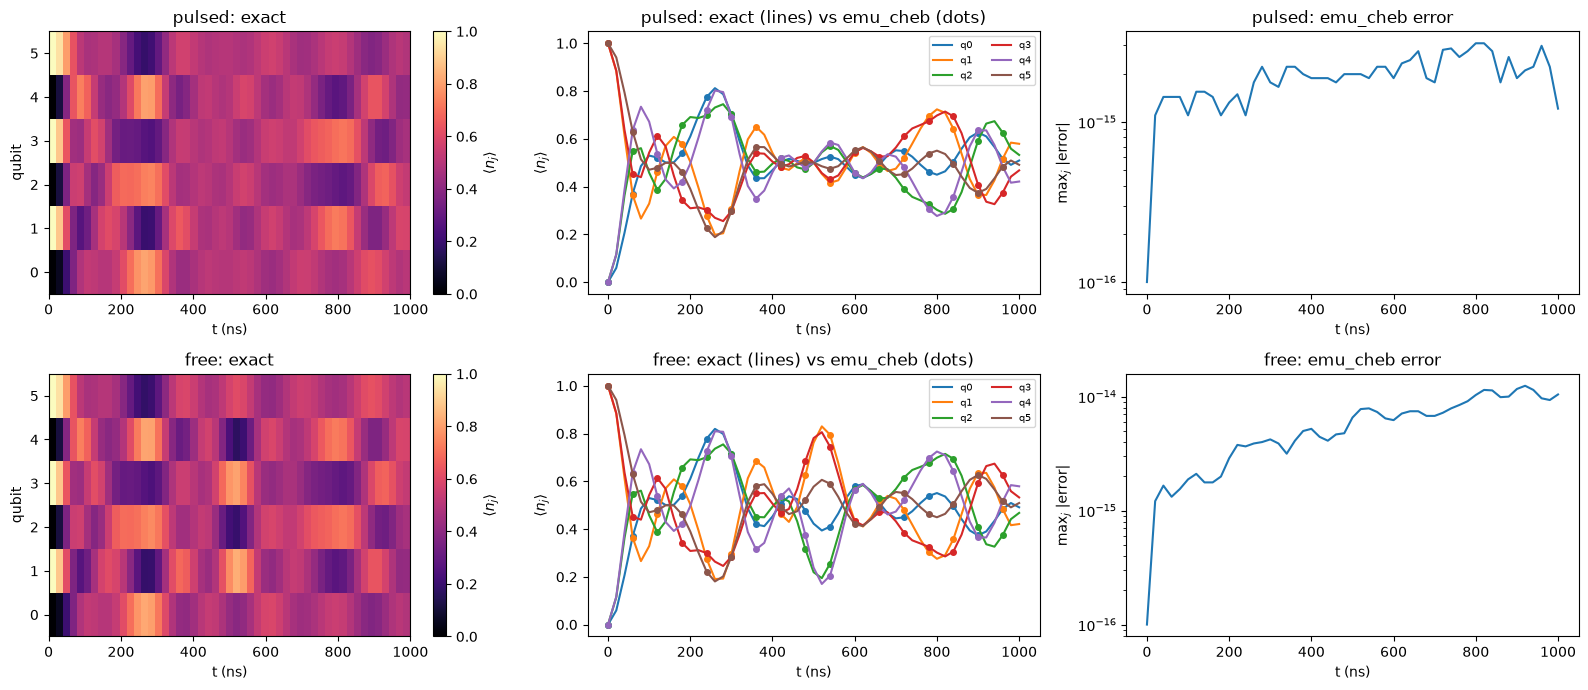

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
tt = np.array(times) * T
for row, name in zip(axes, sequences):
    im = row[0].imshow(exact[name].T, aspect="auto", origin="lower", extent=(0, T, -0.5, n - 0.5),
                       cmap="magma", vmin=0, vmax=1)
    fig.colorbar(im, ax=row[0], label=r"$\langle n_j \rangle$")
    row[0].set_title(f"{name}: exact"); row[0].set_xlabel("t (ns)"); row[0].set_ylabel("qubit")
    for j in range(n):
        (line,) = row[1].plot(tt, exact[name][:, j], label=f"q{j}")
        row[1].plot(tt[::3], cheb_occ[name][::3, j], "o", color=line.get_color(), ms=4)
    row[1].set_title(f"{name}: exact (lines) vs emu_cheb (dots)")
    row[1].set_xlabel("t (ns)"); row[1].set_ylabel(r"$\langle n_j \rangle$"); row[1].legend(ncol=2, fontsize=7)
    row[2].semilogy(tt, (cheb_occ[name] - exact[name]).abs().max(dim=1).values + 1e-16)
    row[2].set_title(f"{name}: emu_cheb error"); row[2].set_xlabel("t (ns)"); row[2].set_ylabel(r"max$_j$ |error|")
fig.tight_layout()

The error is round-off (~1e-13): emu_cheb propagates the same piecewise-constant drive exactly (Chebyshev series, no
time step, no truncation), where emu-mps' TDVP has a $dt^2$ splitting error for long-range couplings.

## 5. Small noise from a pulser `NoiseModel`

The noise model goes through `PulserData` like for any pulser simulation and arrives as single-qubit Lindblad
operators. emu_cheb runs the Monte Carlo wave-function method of emu-mps, but all `n_traj` trajectories in ONE call
(batched); the per-trajectory occupations (`backend.raw`) give the error bars. Compared with the exact Lindblad
solution.

In [7]:
noise_model = pulser.NoiseModel(dephasing_rate=0.2, depolarizing_rate=0.1)  # 1/µs
n_traj = 1000

noisy = {}
for name, seq in sequences.items():
    sd = heisenberg_sequence_data(seq, noise_model)
    results, backend, seconds = run_cheb(seq, [Occupation(evaluation_times=times)], noise_model, n_traj)
    mc = torch.stack(results.occupation)
    mc_err = backend.raw.occupations.std(0) / n_traj**0.5
    occ_lindblad, purity = exact_lindblad_dynamics(sd)
    noisy[name] = dict(mc=mc, mc_err=mc_err, lindblad=occ_lindblad[rows], purity=purity[rows])
    print(
        f"{name:>6}: {len(sd.lindblad_ops)} Lindblad ops, max |MC - Lindblad| {(mc - occ_lindblad[rows]).abs().max():.3f} "
        f"(MC std. error up to {mc_err.max():.3f}), max |noisy - noiseless| {(occ_lindblad[rows] - exact[name]).abs().max():.3f}, "
        f"final purity {purity[-1]:.3f}; {n_traj} trajectories in {seconds:.1f} s ({backend.raw.stats['optimization']})"
    )

pulsed: 4 Lindblad ops, max |MC - Lindblad| 0.012 (MC std. error up to 0.005), max |noisy - noiseless| 0.120, final purity 0.156; 1000 trajectories in 6.4 s (turbo)


  free: 4 Lindblad ops, max |MC - Lindblad| 0.011 (MC std. error up to 0.005), max |noisy - noiseless| 0.120, final purity 0.162; 1000 trajectories in 3.1 s (turbo)


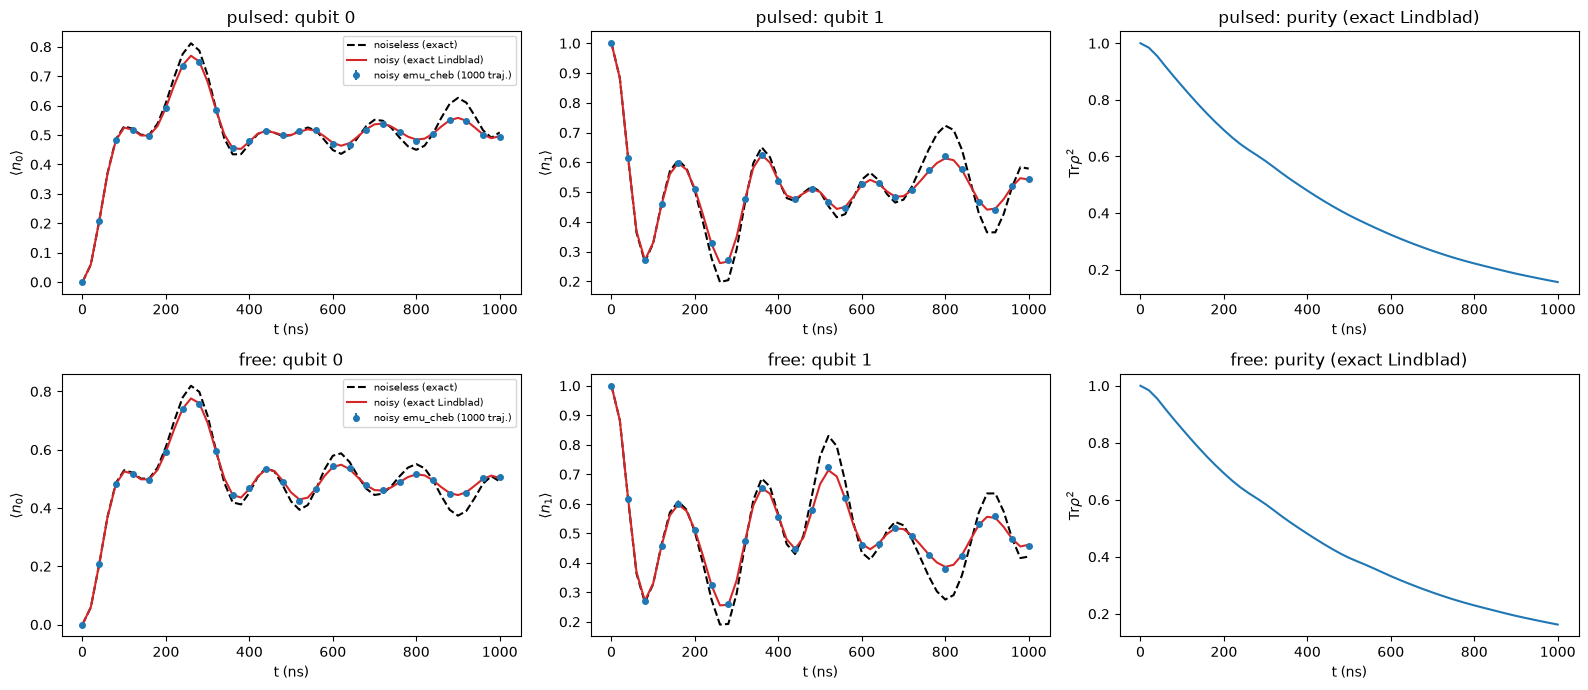

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for row, name in zip(axes, sequences):
    r = noisy[name]
    for ax, j in zip(row[:2], (0, 1)):
        ax.plot(tt, exact[name][:, j], "k--", label="noiseless (exact)")
        ax.plot(tt, r["lindblad"][:, j], "C3", label="noisy (exact Lindblad)")
        ax.errorbar(tt[::2], r["mc"][::2, j], yerr=r["mc_err"][::2, j], fmt="o", color="C0", ms=4,
                    label=f"noisy emu_cheb ({n_traj} traj.)")
        ax.set_title(f"{name}: qubit {j}"); ax.set_xlabel("t (ns)"); ax.set_ylabel(rf"$\langle n_{j} \rangle$")
    row[0].legend(fontsize=7)
    row[2].plot(tt, r["purity"])
    row[2].set_title(f"{name}: purity (exact Lindblad)"); row[2].set_xlabel("t (ns)"); row[2].set_ylabel(r"Tr$\rho^2$")
fig.tight_layout()

**Reading the plots.** In both the pulsed and the free case the trajectory average follows the exact Lindblad solution
within its statistical error (which shrinks as $1/\sqrt{n_{traj}}$), and both deviate visibly from the noiseless
curve. For more atoms, a GPU (`gpu=None` picks it), shot-to-shot noise or other observables (`CorrelationMatrix`,
`BitStrings` with readout errors, `Expectation`), see `emu_cheb/README.md`.